# 1. Import Libraries

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.base import clone

from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, classification_report, confusion_matrix,
    silhouette_score
)

import warnings
warnings.filterwarnings('ignore')

# Plot style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 100

print("---------------- Libraries imported successfully! -----------------")

---------------- Libraries imported successfully! -----------------


# 2. Load the Data

In [4]:
# Update the path if your CSV is in a different location
df = pd.read_csv("ai_model_price_history.csv")

print(f"Shape: {df.shape}")
print(f"\nColumns: {df.columns.tolist()}")
print(f"\nFirst 5 rows:")
df.head().T

Shape: (167787, 9)

Columns: ['week_start', 'model_id', 'model_name', 'developer', 'provider', 'mode', 'input_price_per_1m_tokens', 'output_price_per_1m_tokens', 'max_input_tokens']

First 5 rows:


,0,1,2,3,4
week_start,2024-09-23,2024-09-30,2024-10-07,2024-10-14,2024-10-21
model_id,accounts/fireworks/models/llama-v3p2-90b-visio...,accounts/fireworks/models/llama-v3p2-90b-visio...,accounts/fireworks/models/llama-v3p2-90b-visio...,accounts/fireworks/models/llama-v3p2-90b-visio...,accounts/fireworks/models/llama-v3p2-90b-visio...
model_name,llama-v3p2-90b-vision-instruct,llama-v3p2-90b-vision-instruct,llama-v3p2-90b-vision-instruct,llama-v3p2-90b-vision-instruct,llama-v3p2-90b-vision-instruct
developer,Meta,Meta,Meta,Meta,Meta
provider,fireworks_ai,fireworks_ai,fireworks_ai,fireworks_ai,fireworks_ai
mode,chat,chat,chat,chat,chat
input_price_per_1m_tokens,0.9,0.9,0.9,0.9,0.9
output_price_per_1m_tokens,0.9,0.9,0.9,0.9,0.9
max_input_tokens,16384.0,16384.0,16384.0,16384.0,16384.0


In [5]:
print("Data Types:")
print(df.dtypes)
print("\nBasic Info:")
df.info()

Data Types:
week_start                        str
model_id                          str
model_name                        str
developer                         str
provider                          str
mode                              str
input_price_per_1m_tokens     float64
output_price_per_1m_tokens    float64
max_input_tokens              float64
dtype: object

Basic Info:
<class 'pandas.DataFrame'>
RangeIndex: 167787 entries, 0 to 167786
Data columns (total 9 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   week_start                  167787 non-null  str    
 1   model_id                    167787 non-null  str    
 2   model_name                  167745 non-null  str    
 3   developer                   167787 non-null  str    
 4   provider                    167787 non-null  str    
 5   mode                        167787 non-null  str    
 6   input_price_per_1m_tokens   166742 non-null  float6

# 3. Data Cleaning

In [6]:
print("Missing values BEFORE cleaning:")
print(df.isnull().sum())
print(f"\nTotal rows: {len(df)}")

Missing values BEFORE cleaning:
week_start                        0
model_id                          0
model_name                       42
developer                         0
provider                          0
mode                              0
input_price_per_1m_tokens      1045
output_price_per_1m_tokens     1144
max_input_tokens              13361
dtype: int64

Total rows: 167787


In [7]:
# Convert week_start to datetime
df['week_start'] = pd.to_datetime(df['week_start'])

# Drop rows where BOTH prices are missing
df = df.dropna(subset=['input_price_per_1m_tokens', 'output_price_per_1m_tokens'], how='all').copy()

# Fill model_name first (needed for groupby)
df['model_name'] = df['model_name'].fillna('unknown')

# Fill price missing values using model-wise median, then global median
df['input_price_per_1m_tokens'] = df.groupby('model_name')['input_price_per_1m_tokens'].transform(
    lambda x: x.fillna(x.median())
)
df['output_price_per_1m_tokens'] = df.groupby('model_name')['output_price_per_1m_tokens'].transform(
    lambda x: x.fillna(x.median())
)

df['input_price_per_1m_tokens'] = df['input_price_per_1m_tokens'].fillna(df['input_price_per_1m_tokens'].median())
df['output_price_per_1m_tokens'] = df['output_price_per_1m_tokens'].fillna(df['output_price_per_1m_tokens'].median())

# Fill max_input_tokens
df['max_input_tokens'] = df.groupby('model_name')['max_input_tokens'].transform(
    lambda x: x.fillna(x.median())
)
df['max_input_tokens'] = df['max_input_tokens'].fillna(df['max_input_tokens'].median())

print("Missing values AFTER cleaning:")
print(df.isnull().sum())
print(f"\nCleaned shape: {df.shape}")

# Safety check - should all be 0
assert df[['input_price_per_1m_tokens', 'output_price_per_1m_tokens', 'max_input_tokens']].isnull().sum().sum() == 0, \
    "Still have NaNs after cleaning!"
print("\n --------- No missing values left in key columns -------------")

Missing values AFTER cleaning:
week_start                    0
model_id                      0
model_name                    0
developer                     0
provider                      0
mode                          0
input_price_per_1m_tokens     0
output_price_per_1m_tokens    0
max_input_tokens              0
dtype: int64

Cleaned shape: (166940, 9)

 --------- No missing values left in key columns -------------


# 4. Exploratory Data 

In [8]:
print("=== Descriptive Statistics ===")
df[['input_price_per_1m_tokens', 'output_price_per_1m_tokens', 'max_input_tokens']].describe()

=== Descriptive Statistics ===


,input_price_per_1m_tokens,output_price_per_1m_tokens,max_input_tokens
count,166940.000000,166940.000000,1.669400e+05
mean,2.976644,8.880511,2.275152e+05
std,11.821277,29.082558,5.037974e+05
min,0.000000,0.000000,7.700000e+01
25%,0.130000,0.240000,1.638500e+04
50%,0.500000,1.200000,1.280000e+05
75%,2.000000,7.000000,2.000000e+05
max,250.000000,1000.000000,1.048576e+07


In [9]:
print("=== Unique Counts ===")
print(f"Unique models     : {df['model_name'].nunique()}")
print(f"Unique developers : {df['developer'].nunique()}")
print(f"Unique providers  : {df['provider'].nunique()}")
print(f"Date range        : {df['week_start'].min().date()} → {df['week_start'].max().date()}")

print("\n=== Top 10 Developers ===")
print(df['developer'].value_counts().head(10))

print("\n=== Mode Distribution ===")
print(df['mode'].value_counts())

=== Unique Counts ===
Unique models     : 2270
Unique developers : 43
Unique providers  : 103
Date range        : 2023-09-18 → 2026-09-28

=== Top 10 Developers ===
developer
OpenAI        29266
Meta          24677
Anthropic     17195
Mistral AI    16505
Google        13786
Other         12209
Alibaba       11188
DeepSeek       8329
xAI            4221
Cohere         4149
Name: count, dtype: int64

=== Mode Distribution ===
mode
chat          147763
embedding       9674
completion      6731
responses       2772
Name: count, dtype: int64


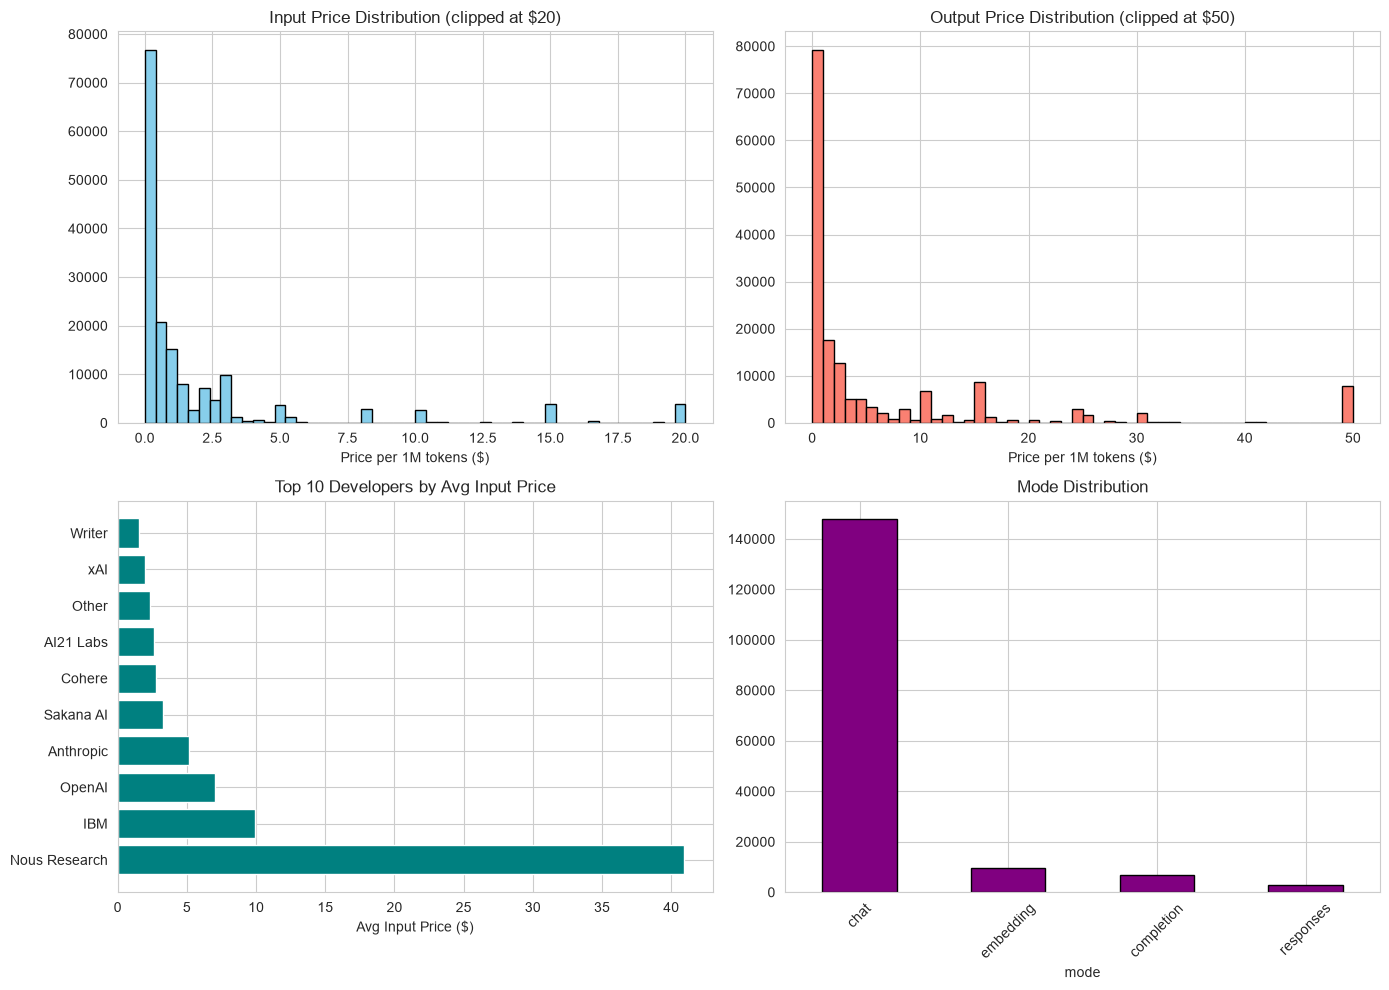

In [10]:
# Visualizations - Overview
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Input price distribution (clipped for better view)
axes[0, 0].hist(df['input_price_per_1m_tokens'].clip(upper=20), bins=50, color='skyblue', edgecolor='black')
axes[0, 0].set_title('Input Price Distribution (clipped at $20)')
axes[0, 0].set_xlabel('Price per 1M tokens ($)')

# Output price distribution
axes[0, 1].hist(df['output_price_per_1m_tokens'].clip(upper=50), bins=50, color='salmon', edgecolor='black')
axes[0, 1].set_title('Output Price Distribution (clipped at $50)')
axes[0, 1].set_xlabel('Price per 1M tokens ($)')

# Top developers by average input price
top_dev = df.groupby('developer')['input_price_per_1m_tokens'].mean().sort_values(ascending=False).head(10)
axes[1, 0].barh(top_dev.index, top_dev.values, color='teal')
axes[1, 0].set_title('Top 10 Developers by Avg Input Price')
axes[1, 0].set_xlabel('Avg Input Price ($)')

# Mode counts
df['mode'].value_counts().plot(kind='bar', ax=axes[1, 1], color='purple', edgecolor='black')
axes[1, 1].set_title('Mode Distribution')
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

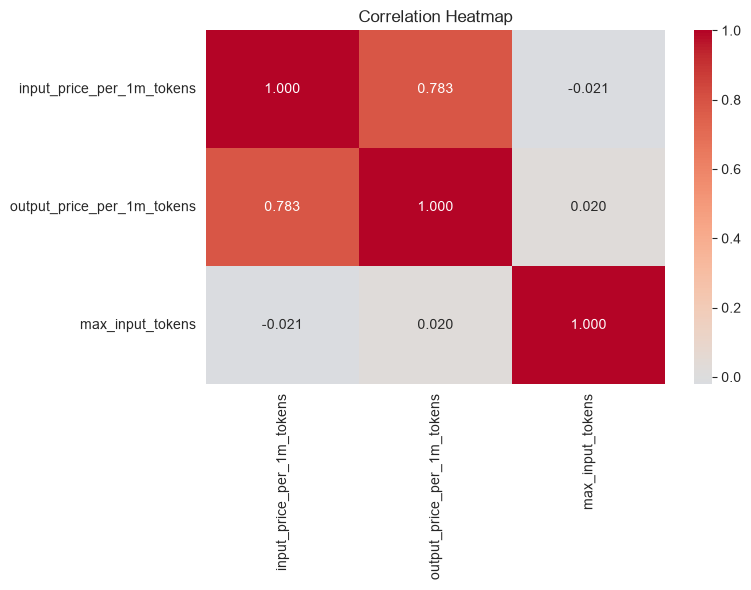

In [11]:
# Correlation heatmap
plt.figure(figsize=(8, 6))
corr = df[['input_price_per_1m_tokens', 'output_price_per_1m_tokens', 'max_input_tokens']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, fmt='.3f')
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

# 5. Feature Engineering

In [12]:
# Time-based features
df['year'] = df['week_start'].dt.year
df['month'] = df['week_start'].dt.month
df['week_of_year'] = df['week_start'].dt.isocalendar().week.astype(int)

# Price-derived features
df['price_ratio'] = df['output_price_per_1m_tokens'] / (df['input_price_per_1m_tokens'] + 1e-6)
df['avg_price'] = (df['input_price_per_1m_tokens'] + df['output_price_per_1m_tokens']) / 2
df['log_input_price'] = np.log1p(df['input_price_per_1m_tokens'])
df['log_output_price'] = np.log1p(df['output_price_per_1m_tokens'])
df['log_max_tokens'] = np.log1p(df['max_input_tokens'])

# Price tier for classification (Low / Medium / High)
# dropna=False so we can see if any NaN appears
df['price_tier'] = pd.qcut(df['avg_price'], q=3, labels=['Low', 'Medium', 'High'])

print("New features created successfully!")
print("\nPrice Tier Distribution:")
print(df['price_tier'].value_counts(dropna=False))

print("\nNaN check after feature engineering:")
print(df[['log_input_price', 'log_max_tokens', 'price_tier', 'year', 'month']].isnull().sum())

print("\nSample of engineered features:")
df[['year', 'month', 'price_ratio', 'avg_price', 'log_input_price', 'price_tier']].head(10)

New features created successfully!

Price Tier Distribution:
price_tier
Low       55733
Medium    55699
High      55508
Name: count, dtype: int64

NaN check after feature engineering:
log_input_price    0
log_max_tokens     0
price_tier         0
year               0
month              0
dtype: int64

Sample of engineered features:


,year,month,price_ratio,avg_price,log_input_price,price_tier
0,2024,9,0.999999,0.9,0.641854,Medium
1,2024,9,0.999999,0.9,0.641854,Medium
2,2024,10,0.999999,0.9,0.641854,Medium
3,2024,10,0.999999,0.9,0.641854,Medium
4,2024,10,0.999999,0.9,0.641854,Medium
5,2024,10,0.999999,0.9,0.641854,Medium
6,2024,11,0.999999,0.9,0.641854,Medium
7,2024,11,0.999999,0.9,0.641854,Medium
8,2024,11,0.999999,0.9,0.641854,Medium
9,2024,11,0.999999,0.9,0.641854,Medium


# 6. Prepare Data for Machine Learning (Train / Test Split)

In [13]:
# Feature columns
feature_cols = [
    'developer', 'provider', 'mode',
    'max_input_tokens', 'year', 'month', 'week_of_year',
    'log_max_tokens'
]

# Build clean working dataframe (drop any row that still has NaN in needed columns)
needed_cols = feature_cols + ['log_input_price', 'price_tier']
df_ml = df[needed_cols].dropna().copy()

print(f"Rows after dropping any remaining NaNs: {len(df_ml)} (from {len(df)})")
print("NaN count in df_ml:", df_ml.isnull().sum().sum())

# --- REGRESSION ---
X_reg = df_ml[feature_cols].copy()
y_reg = df_ml['log_input_price']

# --- CLASSIFICATION ---
X_clf = df_ml[feature_cols].copy()
y_clf = df_ml['price_tier']

# Final safety check
assert X_reg.isnull().sum().sum() == 0, "X_reg still has NaNs"
assert y_reg.isnull().sum() == 0, "y_reg still has NaNs"
assert X_clf.isnull().sum().sum() == 0, "X_clf still has NaNs"
assert y_clf.isnull().sum() == 0, "y_clf still has NaNs"

# Train/Test Split (80% train, 20% test)
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

print(f"\nRegression     → Train: {X_train_reg.shape} | Test: {X_test_reg.shape}")
print(f"Classification → Train: {X_train_clf.shape} | Test: {X_test_clf.shape}")
print("\n ------------ Train/Test split completed successfully (no NaNs) -----------------")

Rows after dropping any remaining NaNs: 166940 (from 166940)
NaN count in df_ml: 0

Regression     → Train: (133552, 8) | Test: (33388, 8)
Classification → Train: (133552, 8) | Test: (33388, 8)

 ------------ Train/Test split completed successfully (no NaNs) -----------------


In [14]:
# Preprocessing Pipeline
# Numeric: median impute + scale
# Categorical: most_frequent impute + one-hot encode
numeric_features = ['max_input_tokens', 'year', 'month', 'week_of_year', 'log_max_tokens']
categorical_features = ['developer', 'provider', 'mode']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), numeric_features),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), categorical_features)
    ],
    remainder='drop'  # ignore any extra columns
)

print("Preprocessor pipeline created successfully!")
print(f"Numeric features    : {numeric_features}")
print(f"Categorical features: {categorical_features}")

Preprocessor pipeline created successfully!
Numeric features    : ['max_input_tokens', 'year', 'month', 'week_of_year', 'log_max_tokens']
Categorical features: ['developer', 'provider', 'mode']


# 7. Regression Models - Predict Log Input Price

In [15]:
# --- Linear Regression ---
print("NaNs in X_train_reg:", X_train_reg.isnull().sum().sum())
print("NaNs in y_train_reg:", y_train_reg.isnull().sum())

mask = ~(X_train_reg.isnull().any(axis=1) | y_train_reg.isnull())
X_train_reg_clean = X_train_reg.loc[mask].copy()
y_train_reg_clean = y_train_reg.loc[mask].copy()
mask_test = ~(X_test_reg.isnull().any(axis=1) | y_test_reg.isnull())
X_test_reg_clean = X_test_reg.loc[mask_test].copy()
y_test_reg_clean = y_test_reg.loc[mask_test].copy()

pipe_lr = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])
pipe_lr.fit(X_train_reg_clean, y_train_reg_clean)
y_pred_lr = pipe_lr.predict(X_test_reg_clean)

print("=== Linear Regression ===")
print(f"MAE  : {mean_absolute_error(y_test_reg_clean, y_pred_lr):.4f}")
print(f"RMSE : {np.sqrt(mean_squared_error(y_test_reg_clean, y_pred_lr)):.4f}")
print(f"R²   : {r2_score(y_test_reg_clean, y_pred_lr):.4f}")

NaNs in X_train_reg: 0
NaNs in y_train_reg: 0
=== Linear Regression ===
MAE  : 0.4251
RMSE : 0.6155
R²   : 0.4600


In [16]:
# --- Ridge Regression ---
pipe_ridge = Pipeline([
    ('preprocessor', preprocessor),
    ('model', Ridge(alpha=1.0))
])
pipe_ridge.fit(X_train_reg_clean, y_train_reg_clean)
y_pred_ridge = pipe_ridge.predict(X_test_reg_clean)

print("=== Ridge Regression ===")
print(f"MAE  : {mean_absolute_error(y_test_reg_clean, y_pred_ridge):.4f}")
print(f"RMSE : {np.sqrt(mean_squared_error(y_test_reg_clean, y_pred_ridge)):.4f}")
print(f"R²   : {r2_score(y_test_reg_clean, y_pred_ridge):.4f}")

=== Ridge Regression ===
MAE  : 0.4251
RMSE : 0.6155
R²   : 0.4600


In [17]:
# --- Random Forest Regressor ---
pipe_rf = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=100,
        max_depth=12,
        random_state=42,
        n_jobs=-1
    ))
])
pipe_rf.fit(X_train_reg_clean, y_train_reg_clean)
y_pred_rf = pipe_rf.predict(X_test_reg_clean)

print("=== Random Forest Regressor ===")
print(f"MAE  : {mean_absolute_error(y_test_reg_clean, y_pred_rf):.4f}")
print(f"RMSE : {np.sqrt(mean_squared_error(y_test_reg_clean, y_pred_rf)):.4f}")
print(f"R²   : {r2_score(y_test_reg_clean, y_pred_rf):.4f}")

=== Random Forest Regressor ===
MAE  : 0.3643
RMSE : 0.5253
R²   : 0.6068


In [18]:
# Cross-Validation on Random Forest
cv_scores = cross_val_score(pipe_rf, X_train_reg_clean, y_train_reg_clean, cv=5, scoring='r2', n_jobs=-1)
print("=== 5-Fold Cross-Validation (Random Forest) ===")
print(f"Mean R² : {cv_scores.mean():.4f}")
print(f"Std R²  : {cv_scores.std():.4f}")
print(f"All folds: {np.round(cv_scores, 4)}")

=== 5-Fold Cross-Validation (Random Forest) ===
Mean R² : 0.6116
Std R²  : 0.0066
All folds: [0.6146 0.6107 0.6153 0.5994 0.6182]


# 8. Classification Models - Predict Price Tier (Low / Medium / High) 

In [19]:
# --- Logistic Regression ---
# Extra safety: ensure no NaNs before fitting
print("NaNs in X_train_clf:", X_train_clf.isnull().sum().sum())
print("NaNs in y_train_clf:", y_train_clf.isnull().sum())

# If any NaN slipped through, drop those rows
mask = ~(X_train_clf.isnull().any(axis=1) | y_train_clf.isnull())
X_train_clf_clean = X_train_clf.loc[mask].copy()
y_train_clf_clean = y_train_clf.loc[mask].copy()

mask_test = ~(X_test_clf.isnull().any(axis=1) | y_test_clf.isnull())
X_test_clf_clean = X_test_clf.loc[mask_test].copy()
y_test_clf_clean = y_test_clf.loc[mask_test].copy()

print(f"Train after NaN drop: {X_train_clf_clean.shape}")
print(f"Test  after NaN drop: {X_test_clf_clean.shape}")

pipe_log = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(max_iter=1000, random_state=42))
])
pipe_log.fit(X_train_clf_clean, y_train_clf_clean)
y_pred_log = pipe_log.predict(X_test_clf_clean)

print("\n=== Logistic Regression ===")
print(f"Accuracy: {accuracy_score(y_test_clf_clean, y_pred_log):.4f}\n")
print(classification_report(y_test_clf_clean, y_pred_log))

NaNs in X_train_clf: 0
NaNs in y_train_clf: 0
Train after NaN drop: (133552, 8)
Test  after NaN drop: (33388, 8)

=== Logistic Regression ===
Accuracy: 0.6868

              precision    recall  f1-score   support

        High       0.74      0.76      0.75     11102
         Low       0.71      0.71      0.71     11146
      Medium       0.61      0.58      0.59     11140

    accuracy                           0.69     33388
   macro avg       0.69      0.69      0.69     33388
weighted avg       0.69      0.69      0.69     33388



In [20]:
# --- Random Forest Classifier ---
# Reuse the cleaned versions from previous cell (or rebuild if needed)
if 'X_train_clf_clean' not in dir():
    mask = ~(X_train_clf.isnull().any(axis=1) | y_train_clf.isnull())
    X_train_clf_clean = X_train_clf.loc[mask].copy()
    y_train_clf_clean = y_train_clf.loc[mask].copy()
    mask_test = ~(X_test_clf.isnull().any(axis=1) | y_test_clf.isnull())
    X_test_clf_clean = X_test_clf.loc[mask_test].copy()
    y_test_clf_clean = y_test_clf.loc[mask_test].copy()

pipe_rfc = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        random_state=42,
        n_jobs=-1
    ))
])
pipe_rfc.fit(X_train_clf_clean, y_train_clf_clean)
y_pred_rfc = pipe_rfc.predict(X_test_clf_clean)

print("=== Random Forest Classifier ===")
print(f"Accuracy: {accuracy_score(y_test_clf_clean, y_pred_rfc):.4f}\n")
print(classification_report(y_test_clf_clean, y_pred_rfc))

=== Random Forest Classifier ===
Accuracy: 0.7135

              precision    recall  f1-score   support

        High       0.80      0.75      0.77     11102
         Low       0.74      0.72      0.73     11146
      Medium       0.62      0.67      0.64     11140

    accuracy                           0.71     33388
   macro avg       0.72      0.71      0.72     33388
weighted avg       0.72      0.71      0.72     33388



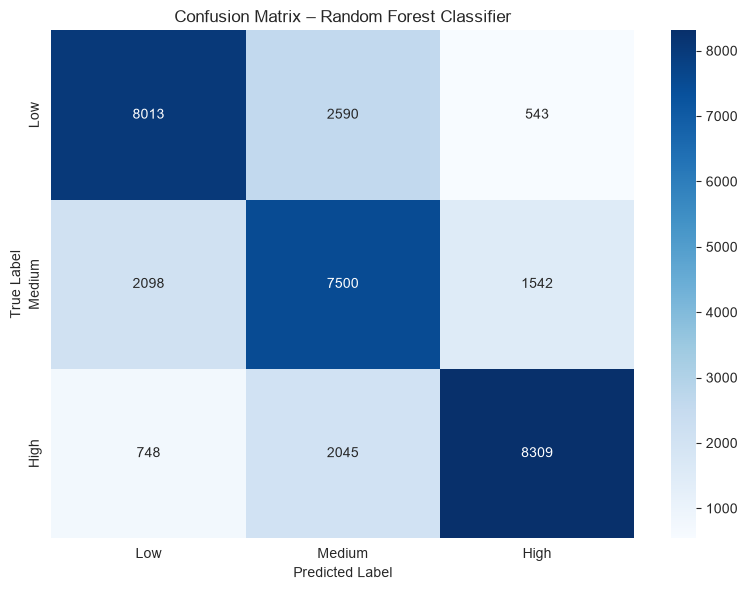

In [21]:
# Confusion Matrix
cm = confusion_matrix(y_test_clf_clean, y_pred_rfc, labels=['Low', 'Medium', 'High'])

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Low', 'Medium', 'High'],
            yticklabels=['Low', 'Medium', 'High'])
plt.title('Confusion Matrix – Random Forest Classifier')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.show()

# 9. Clustering - Group Models by Characterstics

In [22]:
# Use the latest available price for each model
latest = df.sort_values('week_start').groupby('model_name').tail(1).copy()

cluster_features = ['log_input_price', 'log_output_price', 'log_max_tokens']
X_cluster = latest[cluster_features].dropna()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

print(f"Models available for clustering: {X_scaled.shape[0]}")

Models available for clustering: 2270


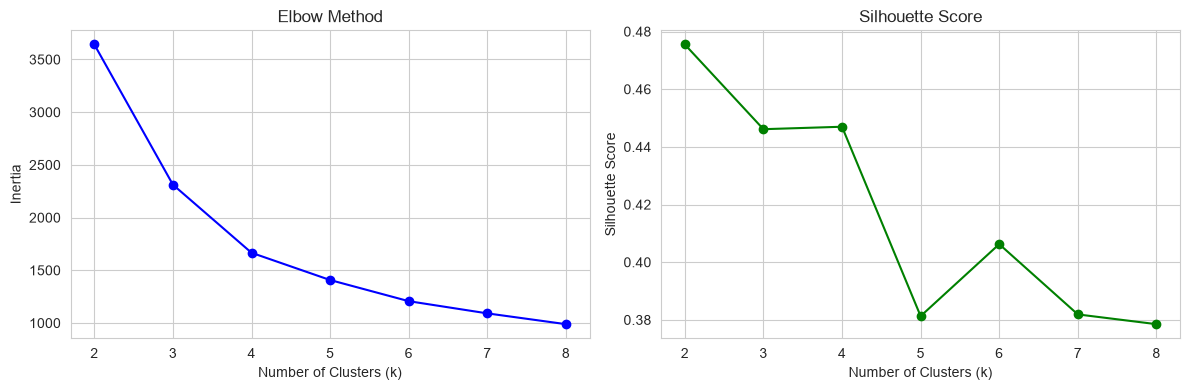

In [23]:
# Elbow Method + Silhouette Score to choose optimal k
inertias = []
silhouettes = []
K_range = range(2, 9)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(K_range, inertias, 'bo-')
axes[0].set_title('Elbow Method')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia')

axes[1].plot(K_range, silhouettes, 'go-')
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')

plt.tight_layout()
plt.show()

In [24]:
# Final clustering with k=4
best_k = 4
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
latest['cluster'] = kmeans.fit_predict(X_scaled)

print(f"Cluster distribution (k={best_k}):")
print(latest['cluster'].value_counts().sort_index())

print("\nApproximate cluster centers (original scale):")
centers = scaler.inverse_transform(kmeans.cluster_centers_)
centers_df = pd.DataFrame(centers, columns=cluster_features)
centers_df

Cluster distribution (k=4):
cluster
0     110
1    1024
2     586
3     550
Name: count, dtype: int64

Approximate cluster centers (original scale):


,log_input_price,log_output_price,log_max_tokens
0,2.888832,3.973787,11.989549
1,0.269026,0.590090,12.306307
2,0.246034,0.325870,9.201706
3,1.144260,2.248285,12.719595


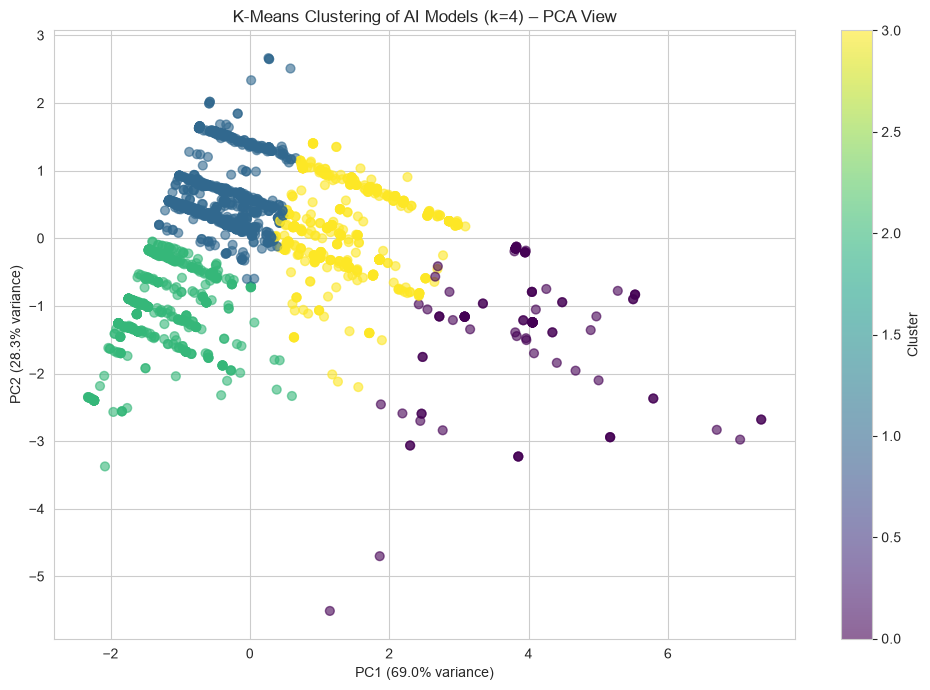

In [25]:
# Visualize clusters with PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 7))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=latest['cluster'],
                      cmap='viridis', alpha=0.6, s=40)
plt.colorbar(scatter, label='Cluster')
plt.title(f'K-Means Clustering of AI Models (k={best_k}) – PCA View')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')
plt.tight_layout()
plt.show()

# 10. Hyperparameter Tuning (GridSearchCV)

In [26]:
pipe_tune = Pipeline([
    ('preprocessor', preprocessor),
    ('model', Ridge())
])

param_grid = {
    'model__alpha': [0.01, 0.1, 1.0, 10.0, 100.0]
}

grid = GridSearchCV(pipe_tune, param_grid, cv=3, scoring='r2', n_jobs=-1)
grid.fit(X_train_reg_clean, y_train_reg_clean)

print("=== Hyperparameter Tuning Results (Ridge) ===")
print(f"Best alpha     : {grid.best_params_['model__alpha']}")
print(f"Best CV R²     : {grid.best_score_:.4f}")
print(f"Test R² (best) : {r2_score(y_test_reg_clean, grid.predict(X_test_reg_clean)):.4f}")

=== Hyperparameter Tuning Results (Ridge) ===
Best alpha     : 0.1
Best CV R²     : 0.4561
Test R² (best) : 0.4600


# 11. Feature Importance

Mismatch detected: names=155, importances=154
Preprocessor was re-fitted after Random Forest. Recovering names...

Feature names : 154
Importances   : 154


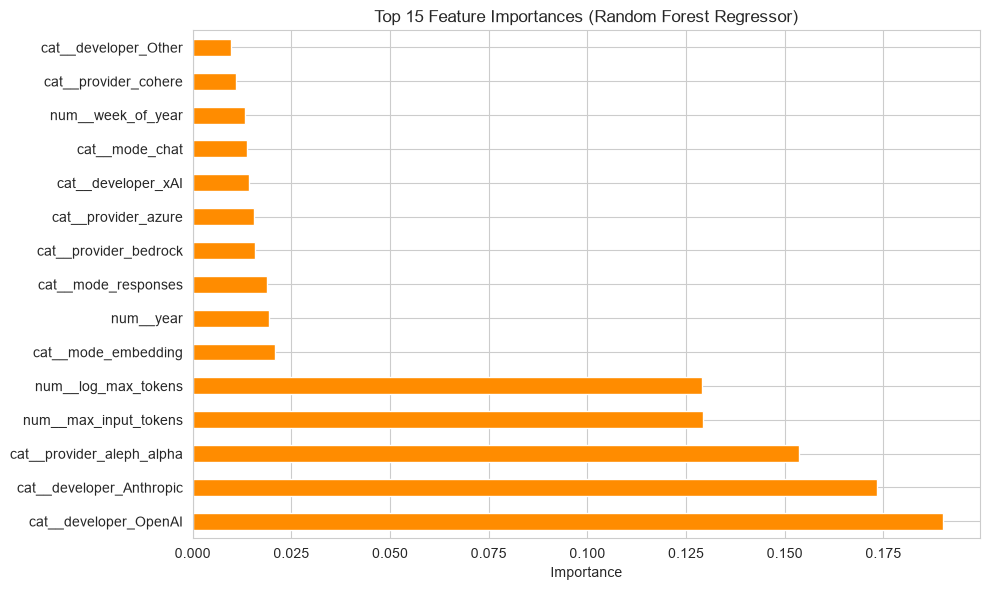

Top 15 most important features:
cat__developer_OpenAI        0.189971
cat__developer_Anthropic     0.173328
cat__provider_aleph_alpha    0.153539
num__max_input_tokens        0.129338
num__log_max_tokens          0.129070
cat__mode_embedding          0.020829
num__year                    0.019224
cat__mode_responses          0.018770
cat__provider_bedrock        0.015769
cat__provider_azure          0.015517
cat__developer_xAI           0.014259
cat__mode_chat               0.013699
num__week_of_year            0.013332
cat__provider_cohere         0.010868
cat__developer_Other         0.009711
dtype: float64


In [31]:
importances = pipe_rf.named_steps['model'].feature_importances_
n_imp = len(importances)

# Try current preprocessor names
try:
    all_feature_names = list(
        pipe_rf.named_steps['preprocessor'].get_feature_names_out()
    )
except Exception:
    all_feature_names = []

if len(all_feature_names) != n_imp:
    print(f"Mismatch detected: names={len(all_feature_names)}, importances={n_imp}")
    print("Preprocessor was re-fitted after Random Forest. Recovering names...\n")

    # Rebuild names from a FRESH clone fitted only on the RF training data
    pre_clone = clone(preprocessor)
    pre_clone.fit(X_train_reg_clean)
    all_feature_names = list(pre_clone.get_feature_names_out())

    # If still off by 1 (rare), trim or pad safely
    if len(all_feature_names) > n_imp:
        all_feature_names = all_feature_names[:n_imp]
    elif len(all_feature_names) < n_imp:
        all_feature_names += [f"extra_{i}" for i in range(n_imp - len(all_feature_names))]

print(f"Feature names : {len(all_feature_names)}")
print(f"Importances   : {n_imp}")

feat_imp = (
    pd.Series(importances, index=all_feature_names)
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(10, 6))
feat_imp.plot(kind='barh', color='darkorange')
plt.title('Top 15 Feature Importances (Random Forest Regressor)')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

print("Top 15 most important features:")
print(feat_imp)